In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("../data/raw/store_sales_data.csv")

In [3]:
df.head()

,Customer ID,Customer Name,Last Name,Date of Birth,Sales,Year,Outlet Type,City Type,Category of Goods,Region,...,Ship Date,Ship Mode,State,Postal Code,Product ID,Sub-Category,Product Name,Quantity,Discount,Profit
0,CUST000001,Curtis,Krause,1973-11-29,3344.69,2023,Large,Tier 1,Fast Food,East,...,2020-04-18,Same Day,West Bengal,700001,PROD000001,Burgers,Burgers - 718,3,0.09,448.24
1,CUST000002,Jeremy,Foster,1987-08-30,37094.41,2022,Medium,Tier 2,Fast Food,East,...,2021-01-11,Standard Class,Punjab,160001,PROD000002,Pizzas,Pizzas - 519,5,0.39,3134.34
2,CUST000003,Ariel,Mccann,1980-12-15,35501.08,2023,Large,Village,Electric Appliances,South,...,2020-08-16,Second Class,Gujarat,380001,PROD000003,Fans,Fans - 395,6,0.07,8324.21
3,CUST000004,Colleen,Maynard,1989-05-23,8969.33,2021,Medium,Village,Dairy Products,East,...,2021-10-16,First Class,West Bengal,700001,PROD000004,Milk,Milk - 798,4,0.18,1962.66
4,CUST000005,Gina,Holden,1957-12-31,35530.44,2021,Small,Village,Sessional Fruits & Vegetables,West,...,2019-01-25,Standard Class,Delhi,110001,PROD000005,Tomatoes,Tomatoes - 442,4,0.27,2843.93


In [4]:
df.shape

(100000, 25)

In [5]:
df.columns.tolist()

['Customer ID',
 'Customer Name',
 'Last Name',
 'Date of Birth',
 'Sales',
 'Year',
 'Outlet Type',
 'City Type',
 'Category of Goods',
 'Region',
 'Country',
 'Segment',
 'Sales Date',
 'Order ID',
 'Order Date',
 'Ship Date',
 'Ship Mode',
 'State',
 'Postal Code',
 'Product ID',
 'Sub-Category',
 'Product Name',
 'Quantity',
 'Discount',
 'Profit']

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 25 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Customer ID        100000 non-null  str    
 1   Customer Name      100000 non-null  str    
 2   Last Name          100000 non-null  str    
 3   Date of Birth      100000 non-null  str    
 4   Sales              100000 non-null  float64
 5   Year               100000 non-null  int64  
 6   Outlet Type        100000 non-null  str    
 7   City Type          100000 non-null  str    
 8   Category of Goods  100000 non-null  str    
 9   Region             100000 non-null  str    
 10  Country            100000 non-null  str    
 11  Segment            100000 non-null  str    
 12  Sales Date         100000 non-null  str    
 13  Order ID           100000 non-null  str    
 14  Order Date         100000 non-null  str    
 15  Ship Date          100000 non-null  str    
 16  Ship Mode     

In [7]:
df.describe()

,Sales,Year,Postal Code,Quantity,Discount,Profit
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,25084.410142,2020.999910,388985.180000,5.493760,0.251320,3755.305114
std,14403.187686,1.413757,184192.704685,2.876102,0.144324,2639.852035
min,100.570000,2019.000000,110001.000000,1.000000,0.000000,6.520000
25%,12618.030000,2020.000000,226001.000000,3.000000,0.130000,1651.105000
50%,25134.695000,2021.000000,380001.000000,5.000000,0.250000,3317.450000
75%,37575.850000,2022.000000,560001.000000,8.000000,0.380000,5363.845000
max,49999.890000,2023.000000,700001.000000,10.000000,0.500000,14563.670000


In [8]:
# Check missing values
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
Customer ID          0
Customer Name        0
Last Name            0
Date of Birth        0
Sales                0
Year                 0
Outlet Type          0
City Type            0
Category of Goods    0
Region               0
Country              0
Segment              0
Sales Date           0
Order ID             0
Order Date           0
Ship Date            0
Ship Mode            0
State                0
Postal Code          0
Product ID           0
Sub-Category         0
Product Name         0
Quantity             0
Discount             0
Profit               0
dtype: int64


In [9]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [10]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [11]:
duplicate_percentage = (duplicate_count / len(df)) * 100

print(f"Duplicate percentage: {duplicate_percentage:.2f}%")

Duplicate percentage: 0.00%


In [12]:
# Checking the existing values in the date columns before converting them into datetime format

date_columns = ["Date of Birth", "Sales Date", "Order Date", "Ship Date"]

for column in date_columns:
    print(f"\n{column}:")
    print(df[column].head())


Date of Birth:
0    1973-11-29
1    1987-08-30
2    1980-12-15
3    1989-05-23
4    1957-12-31
Name: Date of Birth, dtype: str

Sales Date:
0    2023-03-11
1    2023-09-09
2    2022-08-15
3    2021-01-23
4    2020-12-24
Name: Sales Date, dtype: str

Order Date:
0    2020-04-13
1    2021-01-08
2    2020-08-11
3    2021-10-10
4    2019-01-22
Name: Order Date, dtype: str

Ship Date:
0    2020-04-18
1    2021-01-11
2    2020-08-16
3    2021-10-16
4    2019-01-25
Name: Ship Date, dtype: str


In [13]:
# Converting the date columns from string format into datetime format for further time-based analysis

for column in date_columns:
    df[column] = pd.to_datetime(df[column], errors="coerce")

In [14]:
# Verifying that all the selected date columns have been successfully converted into datetime format

df[date_columns].dtypes

Date of Birth    datetime64[us]
Sales Date       datetime64[us]
Order Date       datetime64[us]
Ship Date        datetime64[us]
dtype: object

In [15]:
# Checking for invalid dates created during the datetime conversion process

print("Invalid dates after conversion:")

for column in date_columns:
    print(f"{column}: {df[column].isna().sum()}")

Invalid dates after conversion:
Date of Birth: 0
Sales Date: 0
Order Date: 0
Ship Date: 0


In [16]:
# Checking the minimum and maximum dates to understand the historical period covered by the dataset

print("Order Date range:")
print("Minimum:", df["Order Date"].min())
print("Maximum:", df["Order Date"].max())

print("\nSales Date range:")
print("Minimum:", df["Sales Date"].min())
print("Maximum:", df["Sales Date"].max())

Order Date range:
Minimum: 2019-01-01 00:00:00
Maximum: 2023-12-31 00:00:00

Sales Date range:
Minimum: 2019-01-01 00:00:00
Maximum: 2023-12-31 00:00:00


In [17]:
# Checking whether the existing Year column matches the year extracted from the Order Date column

year_mismatch = (df["Year"] != df["Order Date"].dt.year).sum()

print("Number of Year mismatches:", year_mismatch)

Number of Year mismatches: 80023


In [18]:
# Checking whether the existing Year column matches the year extracted from the Sales Date column

sales_year_mismatch = (df["Year"] != df["Sales Date"].dt.year).sum()

print("Number of Sales Year mismatches:", sales_year_mismatch)

Number of Sales Year mismatches: 79888


In [19]:
# Comparing the year distribution of the existing Year column with the year extracted from the Order Date column

print("Existing Year column:")
print(df["Year"].value_counts().sort_index())

print("\nYear extracted from Order Date:")
print(df["Order Date"].dt.year.value_counts().sort_index())

Existing Year column:
Year
2019    19953
2020    20045
2021    20095
2022    19872
2023    20035
Name: count, dtype: int64

Year extracted from Order Date:
Order Date
2019    20054
2020    19951
2021    19983
2022    19991
2023    20021
Name: count, dtype: int64


In [20]:
# Comparing the Order Date and Sales Date values row by row to identify whether both columns represent the same dates

date_mismatch = (df["Order Date"] != df["Sales Date"]).sum()

print("Number of Order Date and Sales Date mismatches:", date_mismatch)

Number of Order Date and Sales Date mismatches: 99937


In [21]:
# Calculating the number of days between the Order Date and Sales Date to understand the relationship between both date fields

date_difference = (df["Sales Date"] - df["Order Date"]).dt.days

print("Minimum difference:", date_difference.min())
print("Maximum difference:", date_difference.max())
print("Average difference:", date_difference.mean())

print("\nDifference distribution:")
print(date_difference.value_counts().sort_index().head(20))

Minimum difference: -1824
Maximum difference: 1821
Average difference: 1.10681

Difference distribution:
-1824    1
-1820    1
-1813    1
-1809    1
-1808    1
-1807    1
-1806    1
-1805    1
-1803    2
-1802    1
-1799    1
-1797    2
-1796    2
-1795    1
-1794    1
-1789    1
-1788    1
-1786    2
-1785    2
-1783    3
Name: count, dtype: int64


In [22]:
# Checking whether any orders have a Ship Date that occurs before the corresponding Order Date

ship_date_mismatch = (df["Ship Date"] < df["Order Date"]).sum()

print("Orders with Ship Date before Order Date:", ship_date_mismatch)

Orders with Ship Date before Order Date: 0


In [23]:
# Checking whether Quantity and Discount contain values outside their expected valid ranges

print("Quantity below 1:", (df["Quantity"] < 1).sum())
print("Discount below 0:", (df["Discount"] < 0).sum())
print("Discount above 0.50:", (df["Discount"] > 0.50).sum())

Quantity below 1: 0
Discount below 0: 0
Discount above 0.50: 0


In [24]:
# Checking whether Sales and Profit contain negative or zero values that could indicate invalid records

print("Sales less than or equal to 0:", (df["Sales"] <= 0).sum())
print("Profit less than or equal to 0:", (df["Profit"] <= 0).sum())

Sales less than or equal to 0: 0
Profit less than or equal to 0: 0


In [25]:
# Checking the unique values in the main categorical columns to identify inconsistent or unexpected entries

categorical_columns = [
    "Outlet Type",
    "City Type",
    "Category of Goods",
    "Region",
    "Country",
    "Segment",
    "Ship Mode",
    "State",
    "Sub-Category"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())


Outlet Type:
<ArrowStringArray>
['Large', 'Medium', 'Small']
Length: 3, dtype: str

City Type:
<ArrowStringArray>
['Tier 1', 'Tier 2', 'Village']
Length: 3, dtype: str

Category of Goods:
<ArrowStringArray>
[                    'Fast Food',           'Electric Appliances',
                'Dairy Products', 'Sessional Fruits & Vegetables',
                     'Furniture',               'Household Items']
Length: 6, dtype: str

Region:
<ArrowStringArray>
['East', 'South', 'West', 'North']
Length: 4, dtype: str

Country:
<ArrowStringArray>
['India']
Length: 1, dtype: str

Segment:
<ArrowStringArray>
['Consumer', 'Corporate']
Length: 2, dtype: str

Ship Mode:
<ArrowStringArray>
['Same Day', 'Standard Class', 'Second Class', 'First Class']
Length: 4, dtype: str

State:
<ArrowStringArray>
[   'West Bengal',         'Punjab',        'Gujarat',          'Delhi',
     'Tamil Nadu',      'Rajasthan',  'Uttar Pradesh', 'Madhya Pradesh',
      'Karnataka',    'Maharashtra']
Length: 10, dtype: st

In [26]:
# Checking the categorical columns for leading or trailing spaces that could create inconsistent category values

for column in categorical_columns:
    space_count = df[column].astype(str).str.strip().ne(df[column].astype(str)).sum()
    print(f"{column}: {space_count} values with leading or trailing spaces")

Outlet Type: 0 values with leading or trailing spaces
City Type: 0 values with leading or trailing spaces
Category of Goods: 0 values with leading or trailing spaces
Region: 0 values with leading or trailing spaces
Country: 0 values with leading or trailing spaces
Segment: 0 values with leading or trailing spaces
Ship Mode: 0 values with leading or trailing spaces
State: 0 values with leading or trailing spaces
Sub-Category: 0 values with leading or trailing spaces


In [27]:
# Checking the numerical columns for potential extreme outliers using the interquartile range method

numerical_columns = ["Sales", "Quantity", "Discount", "Profit"]

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = ((df[column] < lower_bound) | (df[column] > upper_bound)).sum()

    print(f"{column}:")
    print(f"  Lower Bound: {lower_bound:.2f}")
    print(f"  Upper Bound: {upper_bound:.2f}")
    print(f"  Outliers: {outlier_count}")

Sales:
  Lower Bound: -24818.70
  Upper Bound: 75012.58
  Outliers: 0
Quantity:
  Lower Bound: -4.50
  Upper Bound: 15.50
  Outliers: 0
Discount:
  Lower Bound: -0.24
  Upper Bound: 0.76
  Outliers: 0
Profit:
  Lower Bound: -3918.01
  Upper Bound: 10932.96
  Outliers: 1213


In [28]:
# Inspecting the transactions with unusually high Profit values to determine whether they are valid business records

Q1 = df["Profit"].quantile(0.25)
Q3 = df["Profit"].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

profit_outliers = df[df["Profit"] > upper_bound]

print("Number of Profit outliers:", len(profit_outliers))

display(
    profit_outliers[
        ["Order ID", "Order Date", "Customer Name", "Product Name",
         "Category of Goods", "Sub-Category", "Quantity",
         "Sales", "Discount", "Profit"]
    ].sort_values("Profit", ascending=False).head(20)
)

Number of Profit outliers: 1213


,Order ID,Order Date,Customer Name,Product Name,Category of Goods,Sub-Category,Quantity,Sales,Discount,Profit
9070,ORD009071,2020-11-11,Richard,Fans - 623,Electric Appliances,Fans,5,48854.57,0.00,14563.67
68152,ORD068153,2021-12-14,Mark,Sofas - 134,Furniture,Sofas,4,49047.06,0.01,14435.41
88430,ORD088431,2021-07-08,Joseph,Washing Machines - 853,Electric Appliances,Washing Machines,5,49665.66,0.03,14373.91
57696,ORD057697,2022-02-11,Eric,Utensils - 335,Household Items,Utensils,10,49672.43,0.02,14239.52
19876,ORD019877,2021-03-19,Erin,Microwaves - 252,Electric Appliances,Microwaves,8,49223.43,0.01,14184.06
84973,ORD084974,2020-09-13,Corey,Yogurt - 607,Dairy Products,Yogurt,9,49591.83,0.03,14103.18
39747,ORD039748,2022-10-14,Rose,Utensils - 769,Household Items,Utensils,4,49773.85,0.02,14018.97
18420,ORD018421,2023-02-02,Summer,Carrots - 674,Sessional Fruits & Vegetables,Carrots,8,48446.32,0.01,13999.82
93697,ORD093698,2021-06-21,Kyle,Pizzas - 379,Fast Food,Pizzas,9,48124.34,0.01,13985.70
12887,ORD012888,2022-06-14,Bethany,Washing Machines - 862,Electric Appliances,Washing Machines,10,48722.16,0.02,13979.26


In [29]:
# Confirming that the identified Profit outliers are valid records and will be retained in the cleaned dataset

print("Profit outliers identified:", len(profit_outliers))
print("Profit outliers retained:", len(profit_outliers))
print("Records removed due to Profit outliers: 0")

Profit outliers identified: 1213
Profit outliers retained: 1213
Records removed due to Profit outliers: 0


In [30]:
# Creating reliable year, month, quarter, and year-month features from the Order Date column for analysis and forecasting

df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Quarter"] = df["Order Date"].dt.quarter
df["Year-Month"] = df["Order Date"].dt.to_period("M")

print("Time features created successfully.")
display(df[["Order Date", "Year", "Month", "Quarter", "Year-Month"]].head())

Time features created successfully.


,Order Date,Year,Month,Quarter,Year-Month
0,2020-04-13,2020,4,2,2020-04
1,2021-01-08,2021,1,1,2021-01
2,2020-08-11,2020,8,3,2020-08
3,2021-10-10,2021,10,4,2021-10
4,2019-01-22,2019,1,1,2019-01


In [31]:
# Checking the customer and order identifiers for missing values and duplicate identifiers before using them for RFM analysis

print("Missing Customer IDs:", df["Customer ID"].isna().sum())
print("Missing Order IDs:", df["Order ID"].isna().sum())

print("\nUnique Customers:", df["Customer ID"].nunique())
print("Unique Orders:", df["Order ID"].nunique())

print("\nDuplicate Customer ID values:", df["Customer ID"].duplicated().sum())
print("Duplicate Order ID values:", df["Order ID"].duplicated().sum())

Missing Customer IDs: 0
Missing Order IDs: 0

Unique Customers: 100000
Unique Orders: 100000

Duplicate Customer ID values: 0
Duplicate Order ID values: 0


In [32]:
# Checking the product identifiers for missing values and duplicate values before performing product performance analysis

print("Missing Product IDs:", df["Product ID"].isna().sum())
print("Unique Products:", df["Product ID"].nunique())
print("Duplicate Product ID values:", df["Product ID"].duplicated().sum())

Missing Product IDs: 0
Unique Products: 100000
Duplicate Product ID values: 0


In [33]:
# Checking the Date of Birth values for missing dates and unrealistic future dates before completing data validation

print("Missing Date of Birth values:", df["Date of Birth"].isna().sum())
print("Future Date of Birth values:", (df["Date of Birth"] > pd.Timestamp.today()).sum())

print("\nDate of Birth range:")
print("Earliest:", df["Date of Birth"].min())
print("Latest:", df["Date of Birth"].max())

Missing Date of Birth values: 0
Future Date of Birth values: 0

Date of Birth range:
Earliest: 1950-01-01 00:00:00
Latest: 2018-06-13 00:00:00


In [34]:
# Performing the final data-quality validation before saving the cleaned dataset

print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Invalid Sales values:", (df["Sales"] <= 0).sum())
print("Invalid Quantity values:", (df["Quantity"] <= 0).sum())
print("Invalid Discount values:", ((df["Discount"] < 0) | (df["Discount"] > 0.50)).sum())
print("Invalid Profit values:", (df["Profit"] <= 0).sum())
print("Invalid Order Dates:", df["Order Date"].isna().sum())
print("Invalid Ship Dates:", df["Ship Date"].isna().sum())

Missing values: 0
Duplicate rows: 0
Invalid Sales values: 0
Invalid Quantity values: 0
Invalid Discount values: 0
Invalid Profit values: 0
Invalid Order Dates: 0
Invalid Ship Dates: 0


In [35]:
# Saving the cleaned and validated dataset to the processed data folder for use in the remaining project stages

cleaned_file_path = "../data/processed/cleaned_data.csv"

df.to_csv(cleaned_file_path, index=False)

print("Cleaned dataset saved successfully.")
print("File path:", cleaned_file_path)
print("Final dataset shape:", df.shape)

Cleaned dataset saved successfully.
File path: ../data/processed/cleaned_data.csv
Final dataset shape: (100000, 28)


In [36]:
# Calculating the overall sales, profit, quantity, transaction, customer, and product KPIs to establish the business performance baseline

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
total_products = df["Product ID"].nunique()

print("Overall Business KPIs")
print("---------------------")
print(f"Total Sales: ₹{total_sales:,.2f}")
print(f"Total Profit: ₹{total_profit:,.2f}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Total Products: {total_products:,}")

Overall Business KPIs
---------------------
Total Sales: ₹2,508,441,014.18
Total Profit: ₹375,530,511.43
Total Quantity Sold: 549,376
Total Orders: 100,000
Total Customers: 100,000
Total Products: 100,000


In [37]:
# Analyzing yearly sales, profit, and quantity to understand the historical business performance trend

yearly_sales = df.groupby("Year").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

display(yearly_sales)

,Year,Total_Sales,Total_Profit,Total_Quantity
0,2019,5.021777e+08,75146654.54,110231
1,2020,5.007569e+08,75035318.99,109319
2,2021,5.012826e+08,75126313.00,109943
3,2022,5.019531e+08,75042328.64,109671
4,2023,5.022707e+08,75179896.26,110212


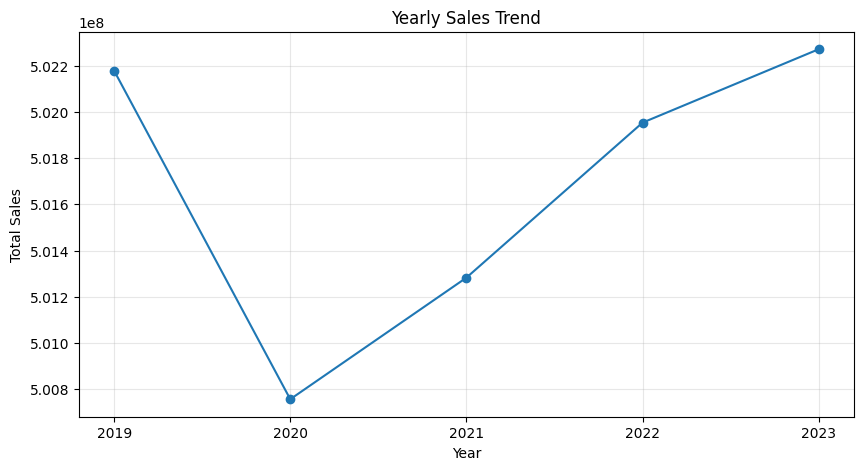

In [38]:
# Visualizing the yearly sales trend to identify changes in overall sales performance across the five-year period

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(yearly_sales["Year"], yearly_sales["Total_Sales"], marker="o")

plt.title("Yearly Sales Trend")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.xticks(yearly_sales["Year"])
plt.grid(True, alpha=0.3)

plt.show()

In [39]:
# Analyzing monthly sales to identify recurring seasonal patterns and variations in sales performance

monthly_sales = df.groupby("Month").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

display(monthly_sales)

,Month,Total_Sales,Total_Profit,Total_Quantity
0,1,2.112620e+08,31898549.77,46035
1,2,1.946797e+08,29250860.07,42552
2,3,2.137710e+08,32068724.55,46704
3,4,2.050980e+08,30752494.80,44888
4,5,2.161449e+08,32199990.07,46599
5,6,2.055897e+08,30839064.71,44867
6,7,2.151258e+08,32249883.11,47190
7,8,2.106741e+08,31373673.08,46632
8,9,2.065905e+08,30823745.37,45188
9,10,2.119533e+08,31762314.08,46271


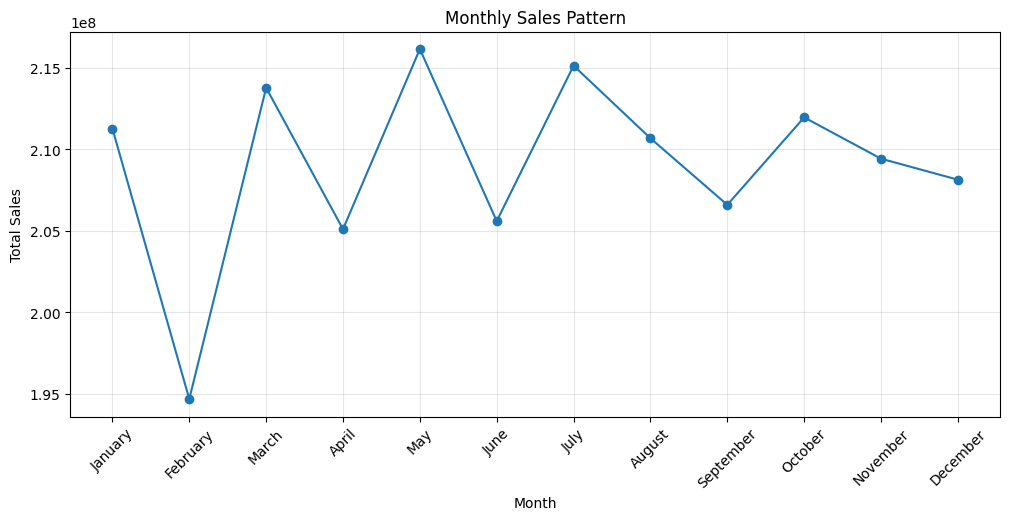

In [40]:
# Visualizing the monthly sales pattern to identify recurring seasonal variations throughout the year

import calendar

monthly_sales["Month_Name"] = monthly_sales["Month"].apply(lambda x: calendar.month_name[x])

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales["Month_Name"], monthly_sales["Total_Sales"], marker="o")

plt.title("Monthly Sales Pattern")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.show()

In [41]:
# Analyzing sales, profit, and quantity across regions to understand regional business performance

region_analysis = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

region_analysis = region_analysis.sort_values("Total_Sales", ascending=False)

display(region_analysis)

,Region,Total_Sales,Total_Profit,Total_Quantity
0,East,6.353223e+08,95147250.29,137903
2,South,6.290598e+08,94220596.30,137537
1,North,6.244511e+08,93099384.98,138324
3,West,6.196078e+08,93063279.86,135612


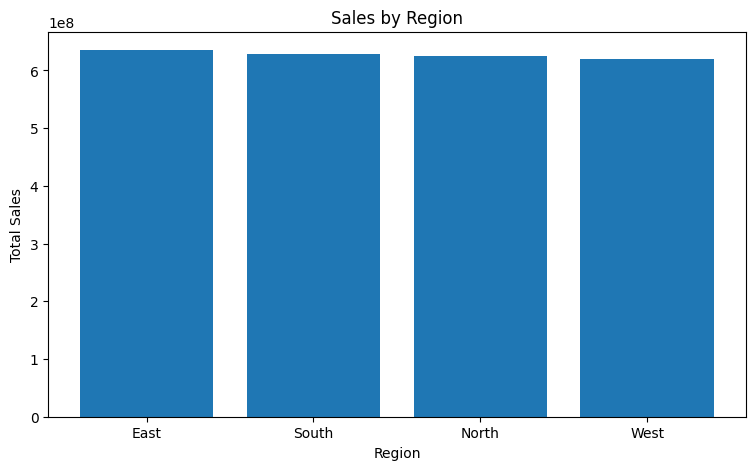

In [42]:
# Visualizing sales performance across regions to compare the contribution of each region to total sales

plt.figure(figsize=(9, 5))
plt.bar(region_analysis["Region"], region_analysis["Total_Sales"])

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")

plt.show()

In [43]:
# Analyzing sales, profit, and quantity across product categories to understand category-level business performance

category_analysis = df.groupby("Category of Goods").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

category_analysis = category_analysis.sort_values("Total_Sales", ascending=False)

display(category_analysis)

,Category of Goods,Total_Sales,Total_Profit,Total_Quantity
5,Sessional Fruits & Vegetables,4.199427e+08,62766851.82,91921
4,Household Items,4.197889e+08,62871293.87,92038
1,Electric Appliances,4.188296e+08,62702992.93,91902
0,Dairy Products,4.180117e+08,62592431.61,91026
2,Fast Food,4.178508e+08,62787837.10,91837
3,Furniture,4.140173e+08,61809104.10,90652


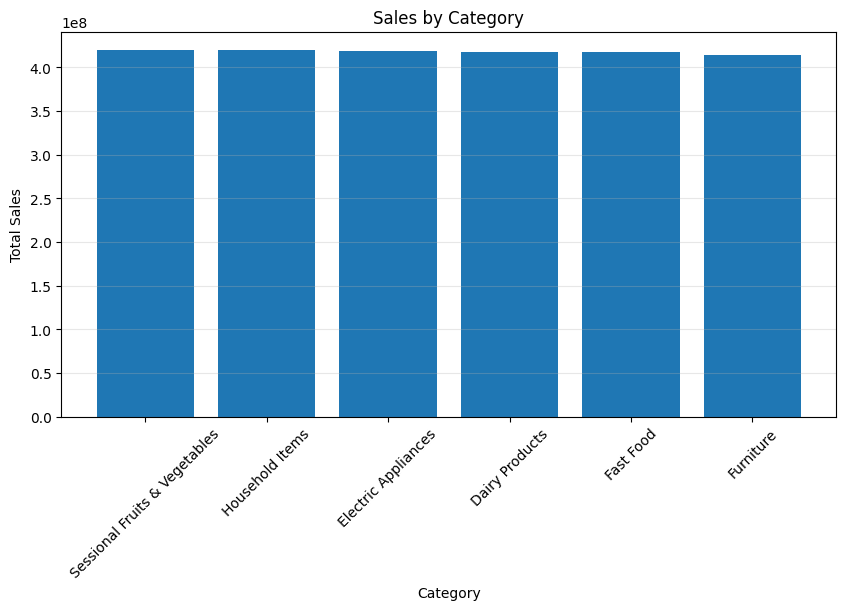

In [44]:
# Visualizing sales performance across product categories to compare the contribution of each category to total sales

plt.figure(figsize=(10, 5))
plt.bar(category_analysis["Category of Goods"], category_analysis["Total_Sales"])

plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [45]:
# Analyzing sales, profit, and quantity across sub-categories to identify detailed product-level performance differences

subcategory_analysis = df.groupby("Sub-Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

subcategory_analysis = subcategory_analysis.sort_values(
    "Total_Sales", ascending=False
)

display(subcategory_analysis)

,Sub-Category,Total_Sales,Total_Profit,Total_Quantity
14,Mops,1.095685e+08,16395505.04,24191
5,Carrots,1.075179e+08,16136518.89,23231
13,Milk,1.058201e+08,15782966.79,23081
12,Microwaves,1.058080e+08,16083504.84,23337
15,Pizzas,1.057033e+08,15817570.33,23394
18,Sofas,1.055018e+08,15787824.47,22970
3,Burgers,1.053565e+08,15829860.41,22851
7,Cheese,1.053360e+08,15770492.08,22705
16,Refrigerators,1.051124e+08,15650138.81,23147
22,Washing Machines,1.049020e+08,15564814.67,22944


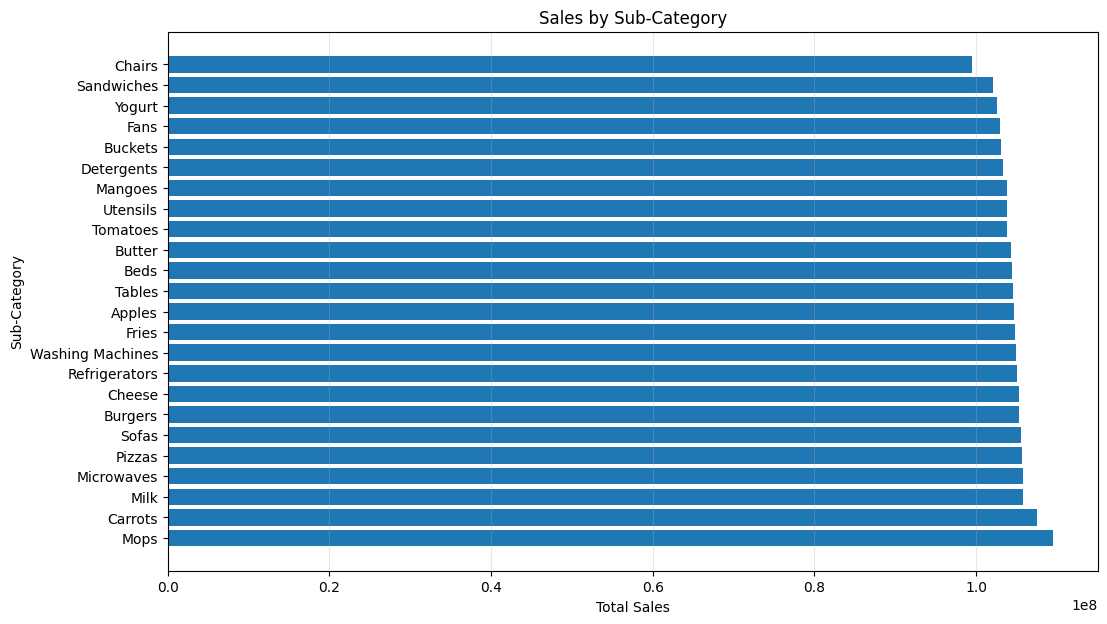

In [46]:
# Visualizing sales across sub-categories to compare detailed product-level sales performance

plt.figure(figsize=(12, 7))
plt.barh(
    subcategory_analysis["Sub-Category"],
    subcategory_analysis["Total_Sales"]
)

plt.title("Sales by Sub-Category")
plt.xlabel("Total Sales")
plt.ylabel("Sub-Category")
plt.grid(axis="x", alpha=0.3)

plt.show()

In [47]:
# Analyzing profit across regions to identify differences in regional profitability

region_profit = df.groupby("Region").agg(
    Total_Profit=("Profit", "sum"),
    Total_Sales=("Sales", "sum")
).reset_index()

region_profit["Profit_Margin"] = (
    region_profit["Total_Profit"] / region_profit["Total_Sales"]
) * 100

region_profit = region_profit.sort_values("Total_Profit", ascending=False)

display(region_profit)

,Region,Total_Profit,Total_Sales,Profit_Margin
0,East,95147250.29,6.353223e+08,14.976218
2,South,94220596.30,6.290598e+08,14.978004
1,North,93099384.98,6.244511e+08,14.908994
3,West,93063279.86,6.196078e+08,15.019707


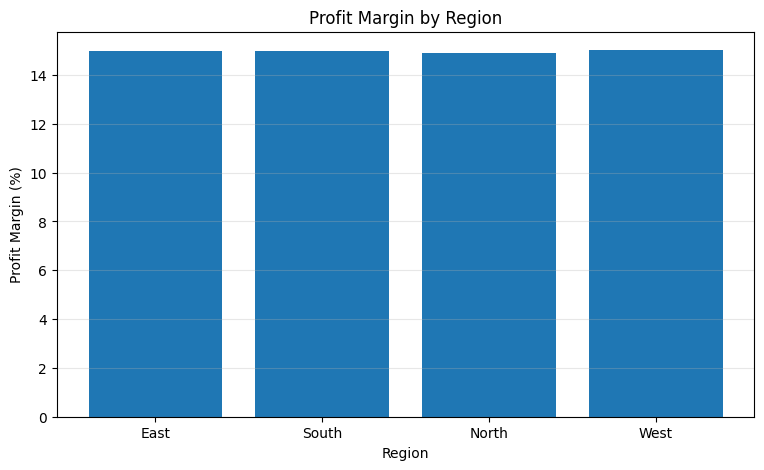

In [48]:
# Visualizing profit margins across regions to compare the profitability efficiency of each region

plt.figure(figsize=(9, 5))
plt.bar(region_profit["Region"], region_profit["Profit_Margin"])

plt.title("Profit Margin by Region")
plt.xlabel("Region")
plt.ylabel("Profit Margin (%)")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [49]:
'''
Profit is consistently distributed across the four regions, with only a small difference in total profit. 
The profit margin also remains close to 15% for all regions, indicating similar profitability across regional operations.
'''

'\nProfit is consistently distributed across the four regions, with only a small difference in total profit. \nThe profit margin also remains close to 15% for all regions, indicating similar profitability across regional operations.\n'

In [50]:
# Comparing sales and profit across product categories to identify differences between revenue generation and profitability

category_profit_analysis = df.groupby("Category of Goods").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).reset_index()

category_profit_analysis["Profit_Margin"] = (
    category_profit_analysis["Total_Profit"] /
    category_profit_analysis["Total_Sales"]
) * 100

display(category_profit_analysis.sort_values("Total_Sales", ascending=False))

,Category of Goods,Total_Sales,Total_Profit,Profit_Margin
5,Sessional Fruits & Vegetables,4.199427e+08,62766851.82,14.946528
4,Household Items,4.197889e+08,62871293.87,14.976884
1,Electric Appliances,4.188296e+08,62702992.93,14.971003
0,Dairy Products,4.180117e+08,62592431.61,14.973848
2,Fast Food,4.178508e+08,62787837.10,15.026376
3,Furniture,4.140173e+08,61809104.10,14.929111


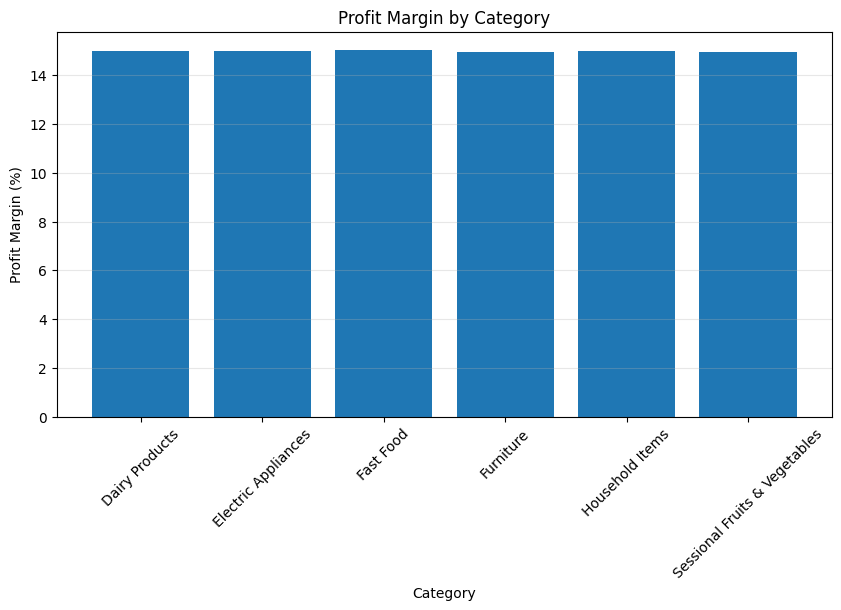

In [51]:
# Visualizing profit margins across categories to compare the profitability efficiency of each product category

plt.figure(figsize=(10, 5))
plt.bar(
    category_profit_analysis["Category of Goods"],
    category_profit_analysis["Profit_Margin"]
)

plt.title("Profit Margin by Category")
plt.xlabel("Category")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [52]:
# Identifying the top 10 products by total sales to understand which products contribute the most revenue

top_products_sales = df.groupby("Product Name").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

top_products_sales = top_products_sales.sort_values(
    "Total_Sales", ascending=False
).head(10)

display(top_products_sales)

,Product Name,Total_Sales,Total_Profit,Total_Quantity
904,Beds - 120,467564.82,77643.63,66
14468,Refrigerators - 338,463807.16,66765.54,64
4389,Butter - 951,458374.84,67379.88,76
13038,Mops - 693,418713.15,58531.96,87
3285,Burgers - 729,408224.56,59266.34,64
8512,Fans - 611,402263.31,60258.06,64
10590,Mangoes - 912,402158.97,70078.99,57
318,Apples - 425,379721.59,65969.62,69
12120,Milk - 660,373800.17,49179.78,63
14836,Refrigerators - 709,373166.48,63501.42,50


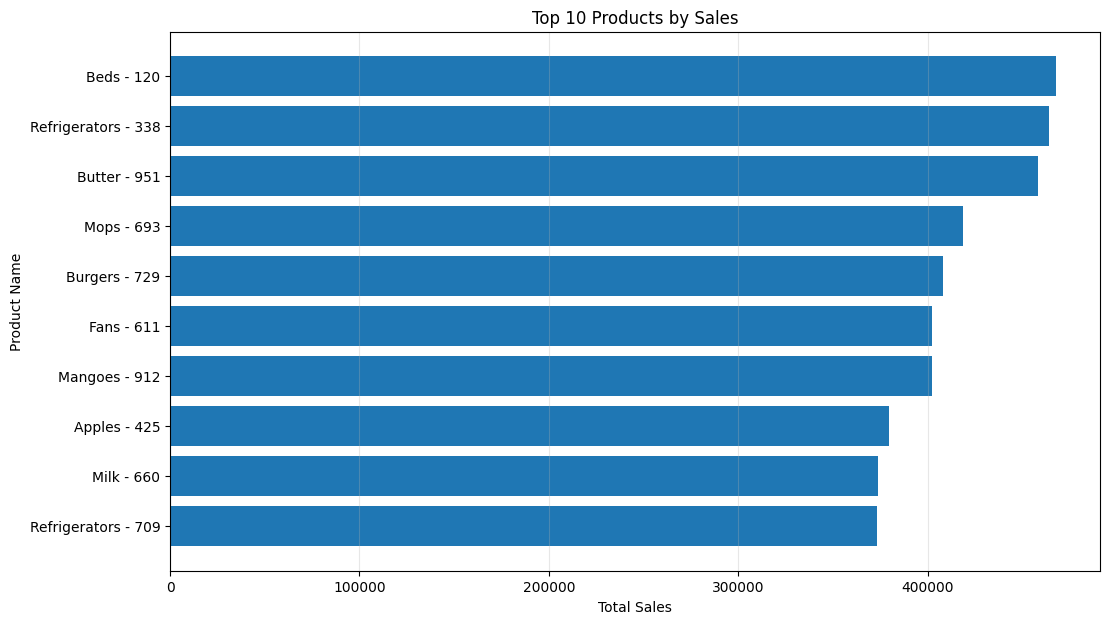

In [53]:
# Visualizing the top 10 products by total sales to compare their revenue contribution

plt.figure(figsize=(12, 7))
plt.barh(
    top_products_sales["Product Name"][::-1],
    top_products_sales["Total_Sales"][::-1]
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Name")
plt.grid(axis="x", alpha=0.3)

plt.show()

In [54]:
# Identifying the top 10 products by total profit to understand which products contribute the most profit

top_products_profit = df.groupby("Product Name").agg(
    Total_Profit=("Profit", "sum"),
    Total_Sales=("Sales", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

top_products_profit = top_products_profit.sort_values(
    "Total_Profit", ascending=False
).head(10)

display(top_products_profit)

,Product Name,Total_Profit,Total_Sales,Total_Quantity
904,Beds - 120,77643.63,467564.82,66
10590,Mangoes - 912,70078.99,402158.97,57
14665,Refrigerators - 538,67496.63,353767.23,69
4389,Butter - 951,67379.88,458374.84,76
14468,Refrigerators - 338,66765.54,463807.16,64
10734,Microwaves - 157,66256.98,362578.77,79
318,Apples - 425,65969.62,379721.59,69
11375,Microwaves - 808,63624.38,352721.83,68
14836,Refrigerators - 709,63501.42,373166.48,50
13190,Mops - 847,62670.68,368502.08,54


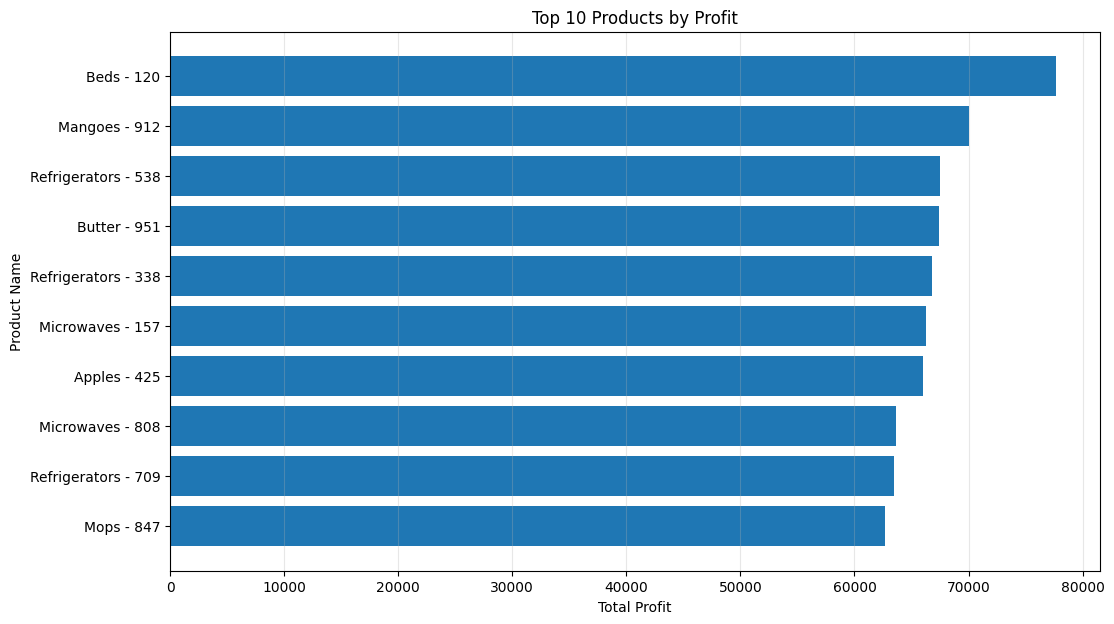

In [55]:
# Visualizing the top 10 products by total profit to compare their contribution to overall profitability

plt.figure(figsize=(12, 7))
plt.barh(
    top_products_profit["Product Name"][::-1],
    top_products_profit["Total_Profit"][::-1]
)

plt.title("Top 10 Products by Profit")
plt.xlabel("Total Profit")
plt.ylabel("Product Name")
plt.grid(axis="x", alpha=0.3)

plt.show()

In [56]:
# Identifying the 10 products with the lowest total sales to detect potentially poor-performing products

lowest_products_sales = df.groupby("Product Name").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

lowest_products_sales = lowest_products_sales.sort_values(
    "Total_Sales", ascending=True
).head(10)

display(lowest_products_sales)

,Product Name,Total_Sales,Total_Profit,Total_Quantity
6781,Cheese - 665,121.20,9.93,3
19772,Washing Machines - 290,302.84,21.50,9
8328,Fans - 426,409.15,36.18,5
16292,Sofas - 378,520.15,70.97,6
1740,Beds - 965,573.56,116.19,6
12660,Mops - 309,609.47,47.38,9
8663,Fans - 766,628.47,81.50,1
10939,Microwaves - 365,707.03,105.52,1
4114,Butter - 669,761.94,129.77,10
14677,Refrigerators - 550,813.42,48.96,2


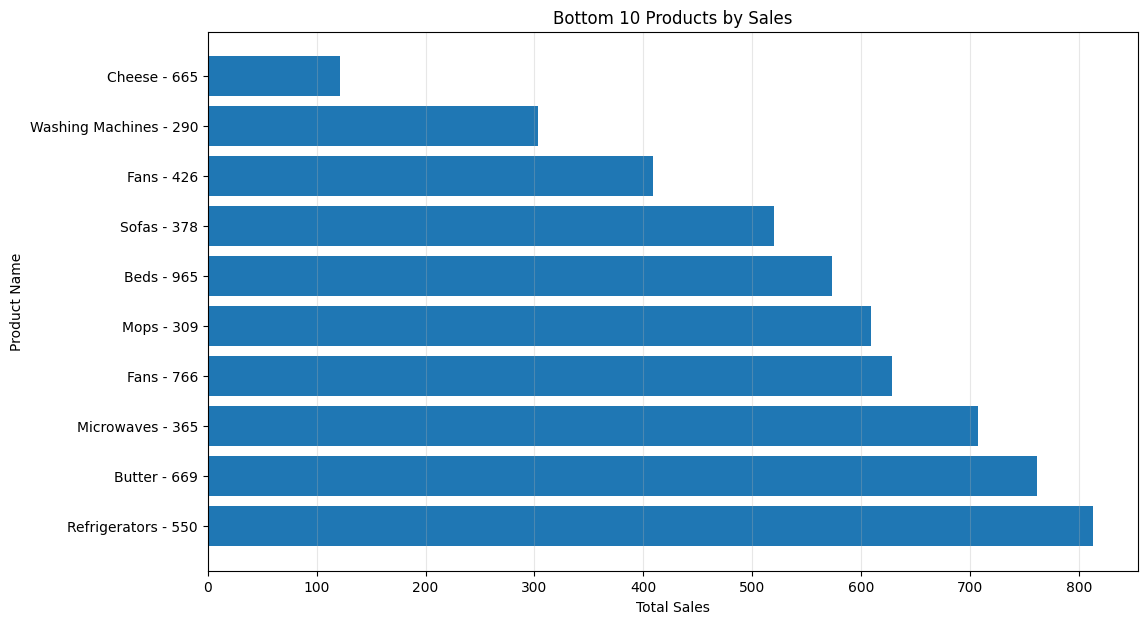

In [57]:
# Visualizing the 10 products with the lowest total sales to highlight products requiring further performance analysis

plt.figure(figsize=(12, 7))
plt.barh(
    lowest_products_sales["Product Name"][::-1],
    lowest_products_sales["Total_Sales"][::-1]
)

plt.title("Bottom 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Name")
plt.grid(axis="x", alpha=0.3)

plt.show()


In [58]:
# Analyzing the relationship between sales and profit to understand whether higher sales are associated with higher profitability

product_performance = df.groupby("Product Name").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).reset_index()

display(product_performance.head())

,Product Name,Total_Sales,Total_Profit
0,Apples - 100,138658.02,12503.05
1,Apples - 102,183266.27,19193.44
2,Apples - 103,97242.51,12167.92
3,Apples - 104,248233.35,32539.75
4,Apples - 105,108641.95,16794.52


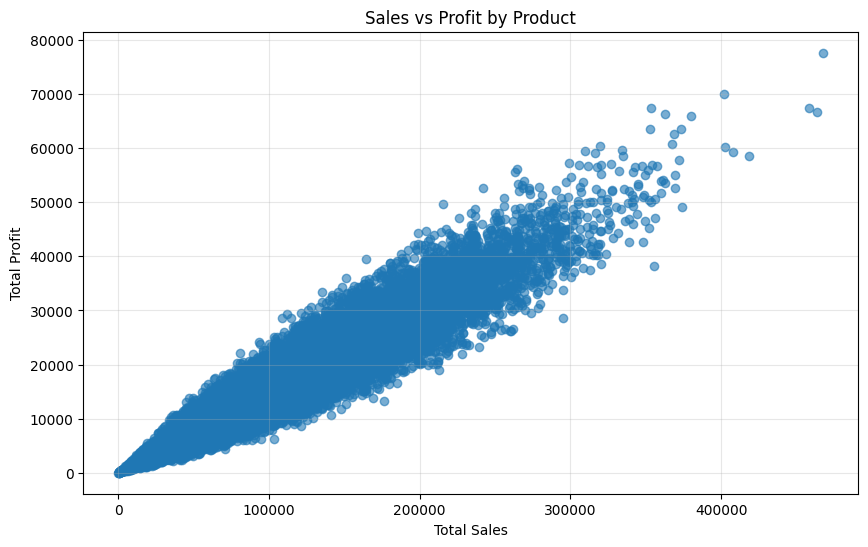

In [59]:
# Visualizing the relationship between product sales and profit to identify how revenue levels relate to profitability

plt.figure(figsize=(10, 6))
plt.scatter(
    product_performance["Total_Sales"],
    product_performance["Total_Profit"],
    alpha=0.6
)

plt.title("Sales vs Profit by Product")
plt.xlabel("Total Sales")
plt.ylabel("Total Profit")
plt.grid(True, alpha=0.3)

plt.show()

In [60]:
# Comparing sales, profit, and profit margin across sub-categories to identify detailed profitability differences

subcategory_profit_analysis = df.groupby("Sub-Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).reset_index()

subcategory_profit_analysis["Profit_Margin"] = (
    subcategory_profit_analysis["Total_Profit"] /
    subcategory_profit_analysis["Total_Sales"]
) * 100

subcategory_profit_analysis = subcategory_profit_analysis.sort_values(
    "Profit_Margin", ascending=False
)

display(subcategory_profit_analysis)

,Sub-Category,Total_Sales,Total_Profit,Profit_Margin
12,Microwaves,1.058080e+08,16083504.84,15.200658
17,Sandwiches,1.020433e+08,15451709.71,15.142305
4,Butter,1.043327e+08,15722503.45,15.069582
3,Burgers,1.053565e+08,15829860.41,15.025041
5,Carrots,1.075179e+08,16136518.89,15.008210
2,Buckets,1.031182e+08,15475820.78,15.007843
21,Utensils,1.038400e+08,15570777.35,14.994971
6,Chairs,9.950227e+07,14914877.04,14.989483
10,Fries,1.047477e+08,15688696.65,14.977612
7,Cheese,1.053360e+08,15770492.08,14.971608


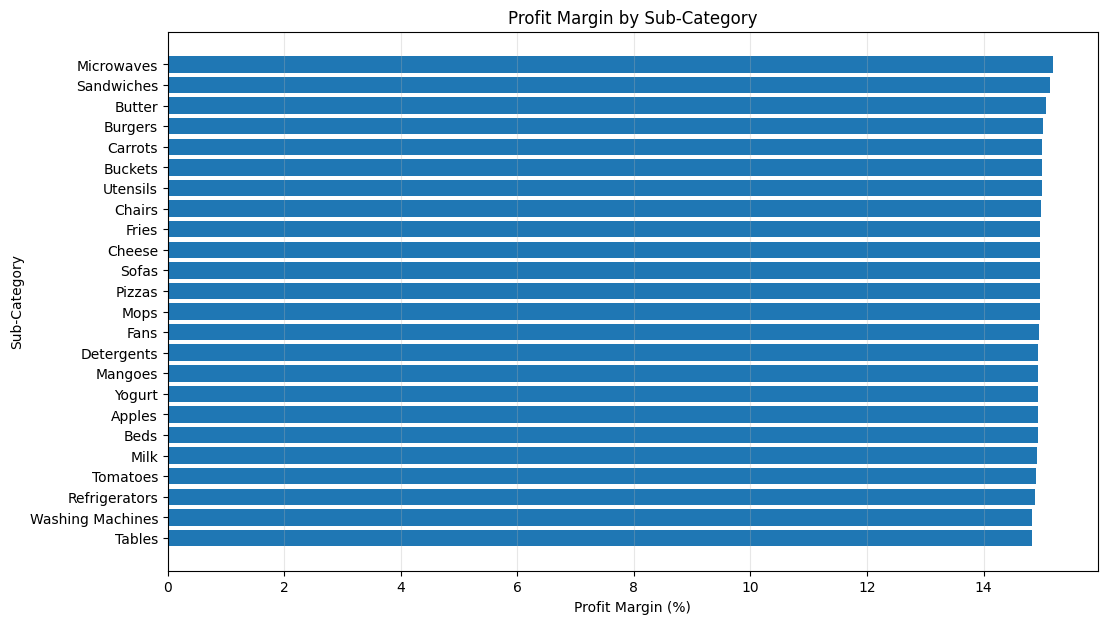

In [61]:
# Visualizing profit margins across sub-categories to compare detailed profitability efficiency

plt.figure(figsize=(12, 7))
plt.barh(
    subcategory_profit_analysis["Sub-Category"][::-1],
    subcategory_profit_analysis["Profit_Margin"][::-1]
)

plt.title("Profit Margin by Sub-Category")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Sub-Category")
plt.grid(axis="x", alpha=0.3)

plt.show()

In [62]:
# Analyzing sales, profit, and quantity across customer segments to understand segment-level business performance

segment_analysis = df.groupby("Segment").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

segment_analysis["Profit_Margin"] = (
    segment_analysis["Total_Profit"] /
    segment_analysis["Total_Sales"]
) * 100

display(segment_analysis)

,Segment,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin
0,Consumer,1.253297e+09,1.877798e+08,274883,14.982864
1,Corporate,1.255144e+09,1.877507e+08,274493,14.958500


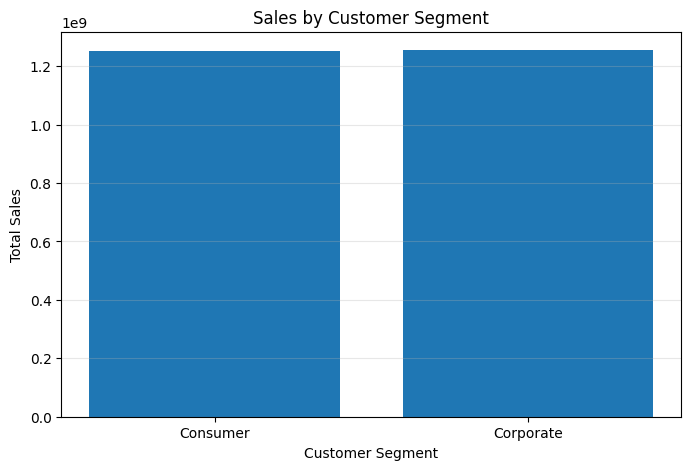

In [63]:
# Visualizing sales across customer segments to compare their contribution to overall revenue

plt.figure(figsize=(8, 5))
plt.bar(
    segment_analysis["Segment"],
    segment_analysis["Total_Sales"]
)

plt.title("Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [64]:
# Analyzing sales, profit, and quantity across outlet types to understand performance differences based on outlet size

outlet_analysis = df.groupby("Outlet Type").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

outlet_analysis["Profit_Margin"] = (
    outlet_analysis["Total_Profit"] /
    outlet_analysis["Total_Sales"]
) * 100

display(outlet_analysis)

,Outlet Type,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin
0,Large,8.410191e+08,1.254250e+08,183993,14.913459
1,Medium,8.409498e+08,1.261441e+08,184258,15.000199
2,Small,8.264721e+08,1.239613e+08,181125,14.998852


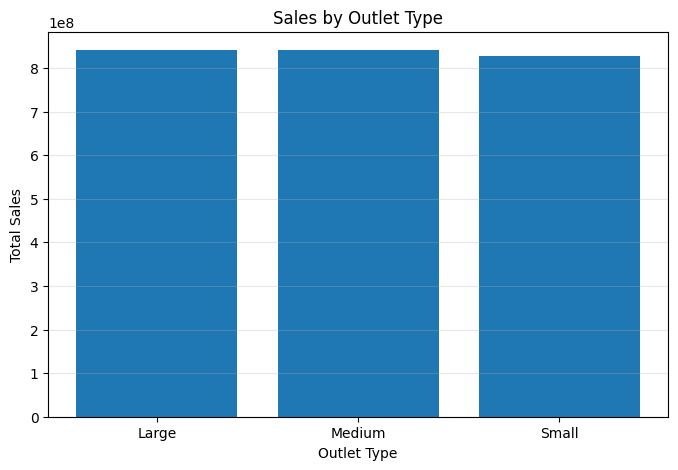

In [65]:
# Visualizing sales across outlet types to compare revenue contribution based on outlet size

plt.figure(figsize=(8, 5))
plt.bar(
    outlet_analysis["Outlet Type"],
    outlet_analysis["Total_Sales"]
)

plt.title("Sales by Outlet Type")
plt.xlabel("Outlet Type")
plt.ylabel("Total Sales")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [66]:
# Analyzing sales, profit, and quantity across city types to understand performance across different market segments

city_type_analysis = df.groupby("City Type").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

city_type_analysis["Profit_Margin"] = (
    city_type_analysis["Total_Profit"] /
    city_type_analysis["Total_Sales"]
) * 100

display(city_type_analysis)

,City Type,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin
0,Tier 1,8.444204e+08,1.265056e+08,184849,14.981351
1,Tier 2,8.354358e+08,1.246817e+08,182840,14.924146
2,Village,8.285848e+08,1.243433e+08,181687,15.006703


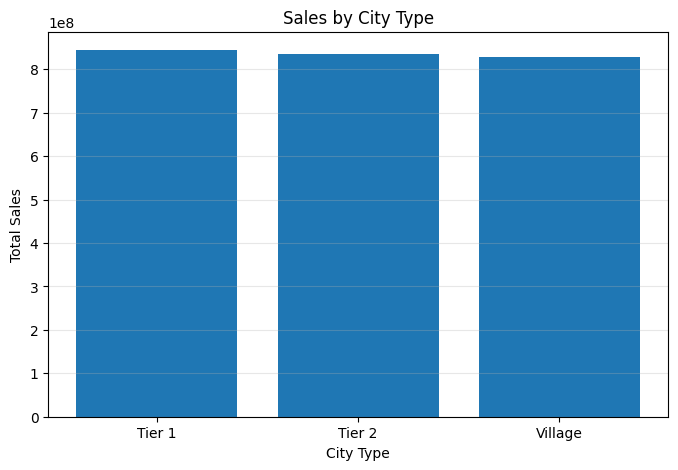

In [67]:
# Visualizing sales across city types to compare revenue contribution from different market locations

plt.figure(figsize=(8, 5))
plt.bar(
    city_type_analysis["City Type"],
    city_type_analysis["Total_Sales"]
)

plt.title("Sales by City Type")
plt.xlabel("City Type")
plt.ylabel("Total Sales")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [68]:
# Analyzing sales, profit, and quantity across shipping modes to understand business performance by delivery method

ship_mode_analysis = df.groupby("Ship Mode").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

ship_mode_analysis["Profit_Margin"] = (
    ship_mode_analysis["Total_Profit"] /
    ship_mode_analysis["Total_Sales"]
) * 100

display(ship_mode_analysis)

,Ship Mode,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin
0,First Class,6.283755e+08,93970261.90,137292,14.954476
1,Same Day,6.272023e+08,93998805.51,137452,14.986998
2,Second Class,6.271439e+08,93898671.05,137273,14.972429
3,Standard Class,6.257193e+08,93662772.97,137359,14.968816


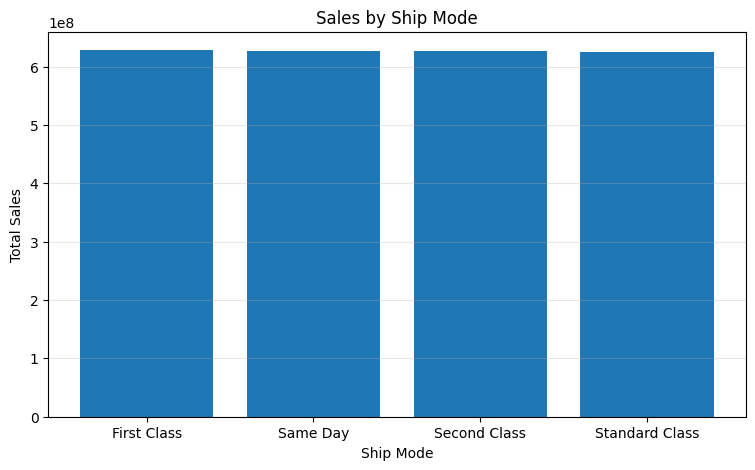

In [69]:
# Visualizing sales across shipping modes to compare revenue contribution from different delivery methods

plt.figure(figsize=(9, 5))
plt.bar(
    ship_mode_analysis["Ship Mode"],
    ship_mode_analysis["Total_Sales"]
)

plt.title("Sales by Ship Mode")
plt.xlabel("Ship Mode")
plt.ylabel("Total Sales")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [70]:
# Analyzing sales, profit, and quantity across states to understand geographical business performance at the state level

state_analysis = df.groupby("State").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

state_analysis["Profit_Margin"] = (
    state_analysis["Total_Profit"] /
    state_analysis["Total_Sales"]
) * 100

state_analysis = state_analysis.sort_values(
    "Total_Sales", ascending=False
)

display(state_analysis)

,State,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin
6,Rajasthan,2.558547e+08,38301042.92,56268,14.969841
5,Punjab,2.539883e+08,37869948.56,55965,14.910118
4,Maharashtra,2.523818e+08,37885432.50,55200,15.011161
3,Madhya Pradesh,2.515571e+08,37640723.38,54633,14.963096
9,West Bengal,2.507483e+08,37738799.38,53936,15.050468
0,Delhi,2.502489e+08,37492737.01,54946,14.982176
2,Karnataka,2.499100e+08,37249521.45,54463,14.905176
7,Tamil Nadu,2.493811e+08,37401926.15,54831,14.997901
1,Gujarat,2.490540e+08,37202469.08,54759,14.937513
8,Uttar Pradesh,2.453169e+08,36747911.00,54375,14.979769


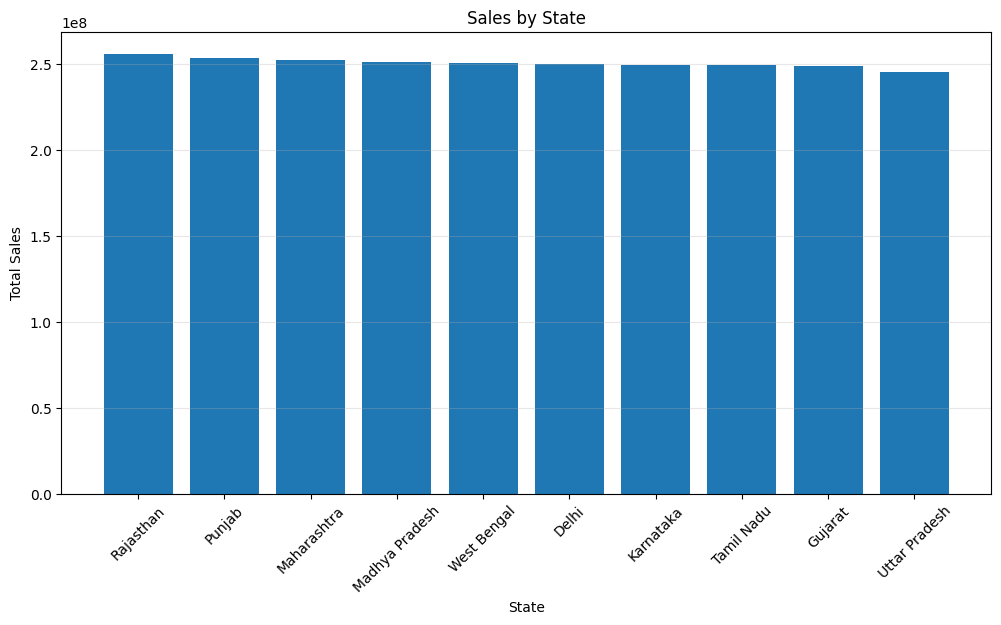

In [71]:
# Visualizing sales across states to compare geographical revenue contribution at the state level

plt.figure(figsize=(12, 6))
plt.bar(
    state_analysis["State"],
    state_analysis["Total_Sales"]
)

plt.title("Sales by State")
plt.xlabel("State")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [72]:
# Summarizing the key EDA findings to establish the final business performance baseline before starting sales forecasting

print("EDA Summary")
print("-----------")

print(f"Total Sales: ₹{df['Sales'].sum():,.2f}")
print(f"Total Profit: ₹{df['Profit'].sum():,.2f}")
print(f"Overall Profit Margin: {(df['Profit'].sum() / df['Sales'].sum()) * 100:.2f}%")

print(f"\nHighest Sales Year: {yearly_sales.loc[yearly_sales['Total_Sales'].idxmax(), 'Year']}")
print(f"Highest Sales Region: {region_analysis.loc[region_analysis['Total_Sales'].idxmax(), 'Region']}")
print(f"Highest Sales Category: {category_analysis.loc[category_analysis['Total_Sales'].idxmax(), 'Category of Goods']}")
print(f"Highest Sales State: {state_analysis.loc[state_analysis['Total_Sales'].idxmax(), 'State']}")
print(f"Highest Sales Outlet Type: {outlet_analysis.loc[outlet_analysis['Total_Sales'].idxmax(), 'Outlet Type']}")
print(f"Highest Sales City Type: {city_type_analysis.loc[city_type_analysis['Total_Sales'].idxmax(), 'City Type']}")
print(f"Highest Sales Ship Mode: {ship_mode_analysis.loc[ship_mode_analysis['Total_Sales'].idxmax(), 'Ship Mode']}")

EDA Summary
-----------
Total Sales: ₹2,508,441,014.18
Total Profit: ₹375,530,511.43
Overall Profit Margin: 14.97%

Highest Sales Year: 2023
Highest Sales Region: East
Highest Sales Category: Sessional Fruits & Vegetables
Highest Sales State: Rajasthan
Highest Sales Outlet Type: Large
Highest Sales City Type: Tier 1
Highest Sales Ship Mode: First Class
